# Actividad 3. Explorando relaciones entre categorías: perfiles sociodemográficos y estado glucémico en NHANES

**Técnicas de Análisis No Supervisado** · Especialización en Análisis Estadístico para Ciencia de Datos · Universidad de La Salle

## 1. Configuración

In [1]:
import os
import sys

# Configuración para Google Colab: clona el repositorio, instala dependencias y descarga los datos.
# En una ejecución local esta celda no hace nada.
if "google.colab" in sys.modules:
    if not os.path.exists("/content/nhanes-no-supervisado"):
        !git clone https://github.com/Juanhv24/nhanes-no-supervisado.git /content/nhanes-no-supervisado
    %cd /content/nhanes-no-supervisado
    !pip install -q -e .
    !python scripts/descargar_datos.py
    # Garantiza que el kernel encuentre el paquete aunque no se reinicie la sesión
    sys.path.insert(0, "/content/nhanes-no-supervisado/src")

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import prince
from scipy.stats import chi2_contingency

from nhanes_no_supervisado.config import SEMILLA, ruta_figuras
from nhanes_no_supervisado.datos import cargar_crudos

RUTA_FIGURAS = ruta_figuras(3)

## 2. Problema y contexto

### 2.1 Pregunta guía y relevancia

Los determinantes sociales de la salud son las circunstancias en que las personas nacen, crecen, viven, trabajan y envejecen, y la Organización Mundial de la Salud les dedicó una comisión específica, cuyo informe final concluyó que las desigualdades en salud tienen un origen marcadamente social (Comisión sobre Determinantes Sociales de la Salud [CSDH], 2008). En el caso de la diabetes, la American Diabetes Association reconoce que factores como el nivel socioeconómico, el entorno del vecindario y la vivienda, el entorno alimentario, incluida la inseguridad alimentaria, y el acceso a la atención en salud se asocian con el riesgo de diabetes y con sus resultados clínicos (Hill-Briggs et al., 2021). De forma coherente, una revisión de alcance en población con diabetes mellitus tipo 2 identificó determinantes estructurales, como la seguridad financiera, e intermediarios, como la afiliación médica, el acceso a los servicios de salud y las condiciones de la vivienda (Heredia-Morales et al., 2023).

En consecuencia, la atención de la diabetes no puede limitarse a los aspectos puramente biomédicos, puesto que las condiciones de vida de cada persona influyen en su posibilidad real de acceder a un tratamiento asequible y equitativo (Organización Panamericana de la Salud [OPS], s.f.). Por ello, identificar qué perfiles sociodemográficos y de estilo de vida concentran los estados glucémicos desfavorables permite orientar la detección temprana y la prevención hacia los grupos en mayor desventaja. Con este propósito, además de las características demográficas, el análisis incorpora dos de los determinantes señalados por la literatura que NHANES mide directamente: la seguridad alimentaria y la cobertura de seguro médico. A partir de lo anterior, la pregunta guía de esta actividad es: *¿Qué perfiles sociodemográficos y de estilo de vida se asocian con el estado glucémico de los adultos?*

Dado que tanto el estado glucémico como las características sociodemográficas son variables categóricas, el análisis de correspondencias resulta adecuado para responderla: el análisis simple permite estudiar la asociación entre dos de ellas a partir de una tabla de contingencia, mientras que el múltiple permite explorar de forma conjunta las relaciones entre varias variables y representarlas en un mismo mapa perceptual.

### 2.2 Base de datos

La Encuesta Nacional de Examen de Salud y Nutrición (NHANES, por sus siglas en inglés) es un programa del Centro Nacional de Estadísticas de Salud (NCHS) de los Centros para el Control y la Prevención de Enfermedades (CDC) de Estados Unidos, diseñado para evaluar el estado de salud y nutrición de su población (National Center for Health Statistics [NCHS], s.f.). La encuesta combina entrevistas en el hogar con exámenes físicos y pruebas de laboratorio, de modo que reúne en un mismo participante características sociodemográficas, hábitos y mediciones clínicas; además, se publica en ciclos de dos años divididos en módulos que se vinculan mediante un identificador único por participante (`SEQN`) (NCHS, s.f.).

En este trabajo se emplea el ciclo 2017–2018, el mismo de la actividad anterior, y se usan seis de sus módulos: demografía (edad, sexo, nivel educativo, raza y origen étnico, y razón entre el ingreso familiar y la línea de pobreza), hemoglobina glicada, a partir de la cual se define el estado glucémico, medidas corporales, para la obesidad abdominal, tabaquismo, seguridad alimentaria y seguro médico.

## 3. Población de estudio

### 3.1 Carga y unión de los módulos

In [3]:
df = cargar_crudos()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9254 entries, 93703 to 102956
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad                   9254 non-null   float64
 1   sexo                   9254 non-null   float64
 2   embarazo               1110 non-null   float64
 3   educacion              5569 non-null   float64
 4   raza_etnia             9254 non-null   float64
 5   ingreso_pobreza        8023 non-null   float64
 6   cintura_cm             7601 non-null   float64
 7   imc                    8005 non-null   float64
 8   hba1c_pct              6045 non-null   float64
 9   glucosa_mgdl           2891 non-null   float64
 10  peso_ayuno             3036 non-null   float64
 11  trigliceridos_mgdl     2834 non-null   float64
 12  hdl_mgdl               6738 non-null   float64
 13  diabetes_dx            8897 non-null   float64
 14  fumo_100               5856 non-null   float64
 15  fuma_actu

### 3.2 Selección de la población

In [4]:
# Adultos de 20 años o más, sin embarazo confirmado y con HbA1c disponible
es_adulto = df["edad"] >= 20
es_embarazada = df["embarazo"] == 1

df_poblacion = df[es_adulto & ~es_embarazada].drop(columns="embarazo")
df_poblacion = df_poblacion.dropna(subset=["hba1c_pct"]).copy()

print(f"Adultos sin embarazo: {(es_adulto & ~es_embarazada).sum():,}")
print(f"Con HbA1c disponible: {len(df_poblacion):,}")

Adultos sin embarazo: 5,514
Con HbA1c disponible: 4,971


La población de estudio se restringe a adultos de 20 años o más, que es el corte habitual en los estudios sobre salud cardiometabólica basados en NHANES (Hirode & Wong, 2020), y se excluyen las participantes con embarazo confirmado, puesto que la gestación modifica de forma marcada el perfil metabólico (Wang et al., 2016). Además, se conservan solo los participantes con hemoglobina glicada (HbA1c) disponible, ya que a partir de ella se define el estado glucémico. A diferencia de la glucosa en ayunas, la HbA1c no requiere ayuno y es uno de los criterios diagnósticos de la diabetes y la prediabetes (American Diabetes Association Professional Practice Committee [ADA], 2025), de modo que el análisis no se limita a la submuestra matutina y conserva un número considerablemente mayor de participantes.

## 4. Variables y recodificación

### 4.1 Frecuencias de las variables codificadas

In [5]:
# Variables que NHANES almacena como códigos numéricos
codificadas = ["sexo", "educacion", "raza_etnia", "seguridad_alimentaria",
               "seguro_medico", "fumo_100", "fuma_actual"]

for columna in codificadas:
    print(f"\n{columna}")
    display(
        df_poblacion[columna].value_counts(dropna=False).sort_index()
        .to_frame("n")
        .assign(porcentaje=lambda t: (t["n"] / t["n"].sum() * 100).round(1))
    )

print(f"Sin ingreso reportado: {df_poblacion['ingreso_pobreza'].isna().sum():,}")
print(f"Sin medición de cintura: {df_poblacion['cintura_cm'].isna().sum():,}")


sexo


,n,porcentaje
sexo,,
1.0,2415,48.6
2.0,2556,51.4



educacion


,n,porcentaje
educacion,,
1.0,426,8.6
2.0,565,11.4
3.0,1188,23.9
4.0,1603,32.2
5.0,1178,23.7
7.0,2,0.0
9.0,9,0.2



raza_etnia


,n,porcentaje
raza_etnia,,
1.0,673,13.5
2.0,475,9.6
3.0,1733,34.9
4.0,1138,22.9
6.0,699,14.1
7.0,253,5.1


... (5 outputs left out)

,n,porcentaje
fumo_100,,
1.0,2105,42.3
2.0,2866,57.7



fuma_actual


,n,porcentaje
fuma_actual,,
1.0,708,14.2
2.0,191,3.8
3.0,1206,24.3
NaN,2866,57.7


Sin ingreso reportado: 645
Sin medición de cintura: 257


Las variables sociodemográficas de NHANES se almacenan como códigos numéricos, por lo que es necesario traducirlas a categorías antes del análisis. Además, varias de ellas incluyen los códigos 7 (se negó a responder) y 9 (no sabe), que no representan una categoría sustantiva y se tratan como faltantes (NCHS, 2020). Por su parte, la variable `fuma_actual` solo se pregunta a quienes han fumado al menos 100 cigarrillos en su vida, de modo que sus faltantes son esperados y se resuelven al combinarla con `fumo_100`.

### 4.2 Recodificación

In [6]:
recod = pd.DataFrame(index=df_poblacion.index)

# Estado glucémico según la HbA1c (ADA, 2025); right=False deja 5,7 en prediabetes y 6,5 en diabetes
recod["estado_glucemico"] = pd.cut(
    df_poblacion["hba1c_pct"],
    bins=[0, 5.7, 6.5, np.inf],
    labels=["Glucemia normal", "Prediabetes", "Diabetes"],
    right=False,
)

# Grupos de edad
recod["grupo_edad"] = pd.cut(
    df_poblacion["edad"],
    bins=[20, 40, 60, np.inf],
    labels=["20 a 39 años", "40 a 59 años", "60 años o más"],
    right=False,
)

# Sexo
recod["sexo"] = df_poblacion["sexo"].map({1: "Hombre", 2: "Mujer"})

# Nivel educativo; los códigos 1 y 2 se unen por su baja frecuencia y 7 y 9 quedan como faltantes
recod["educacion"] = df_poblacion["educacion"].map({
    1: "Menos de bachillerato",
    2: "Menos de bachillerato",
    3: "Bachillerato",
    4: "Universidad incompleta o técnico",
    5: "Universitario o superior",
})

# Raza y origen étnico
recod["raza_etnia"] = df_poblacion["raza_etnia"].map({
    1: "Mexicano-estadounidense",
    2: "Otro hispano",
    3: "Blanco no hispano",
    4: "Negro no hispano",
    6: "Asiático no hispano",
    7: "Otra raza o multirracial",
})

# Razón ingreso/pobreza; np.inf conserva a quienes tienen el valor tope de 5
recod["pobreza"] = pd.cut(
    df_poblacion["ingreso_pobreza"],
    bins=[0, 1, 2, np.inf],
    labels=["Bajo la línea de pobreza", "Cerca de la línea de pobreza", "Por encima de la línea de pobreza"],
    right=False,
)

# Seguridad alimentaria del adulto; los niveles baja y muy baja se unen
recod["seguridad_alimentaria"] = df_poblacion["seguridad_alimentaria"].map({
    1: "Seguridad alimentaria plena",
    2: "Seguridad alimentaria marginal",
    3: "Inseguridad alimentaria",
    4: "Inseguridad alimentaria",
})

# Seguro médico; 7 y 9 quedan como faltantes
recod["seguro_medico"] = df_poblacion["seguro_medico"].map({1: "Con seguro médico", 2: "Sin seguro médico"})

# Tabaquismo a partir de las dos preguntas de SMQ
fumo_100 = df_poblacion["fumo_100"]
fuma_actual = df_poblacion["fuma_actual"]
recod["tabaquismo"] = pd.Series(
    np.select(
        [fumo_100.eq(2), fumo_100.eq(1) & fuma_actual.eq(3), fumo_100.eq(1) & fuma_actual.isin([1, 2])],
        ["Nunca fumador", "Exfumador", "Fumador actual"],
        default=None,
    ),
    index=df_poblacion.index,
)

# Obesidad abdominal: cintura de 102 cm o más en hombres y de 88 cm o más en mujeres (Alberti et al., 2009)
umbral_cintura = np.where(df_poblacion["sexo"].eq(1), 102, 88)
recod["obesidad_abdominal"] = pd.Series(
    np.where(
        df_poblacion["cintura_cm"].isna(),
        None,
        np.where(df_poblacion["cintura_cm"] >= umbral_cintura, "Con obesidad abdominal", "Sin obesidad abdominal"),
    ),
    index=df_poblacion.index,
)

print("Faltantes por variable recodificada:")
display(recod.isna().sum().to_frame("faltantes"))

Faltantes por variable recodificada:


,faltantes
estado_glucemico,0
grupo_edad,0
sexo,0
educacion,11
raza_etnia,0
pobreza,645
seguridad_alimentaria,234
seguro_medico,13
tabaquismo,0
obesidad_abdominal,257


La recodificación sigue tres criterios. En primer lugar, el estado glucémico se define con los umbrales de HbA1c de la American Diabetes Association: menor de 5,7 % para glucemia normal, de 5,7 a 6,4 % para prediabetes y de 6,5 % o más para diabetes (ADA, 2025); de la misma manera, la obesidad abdominal se define con los puntos de corte de cintura para población estadounidense, de 102 cm en hombres y 88 cm en mujeres (Alberti et al., 2009). En segundo lugar, las categorías con una frecuencia muy baja se agrupan con la más cercana, ya que en el análisis de correspondencias las categorías poco frecuentes tienden a ubicarse en los extremos del mapa y a influir de forma desproporcionada en los ejes (Greenacre, 2017); por ello, se unen los dos niveles educativos inferiores y los niveles baja y muy baja de seguridad alimentaria. En tercer lugar, las etiquetas de cada categoría son únicas entre variables (por ejemplo, «Con seguro médico» en lugar de «Sí»), de modo que puedan identificarse sin ambigüedad en los mapas perceptuales.

### 4.3 Base categórica para el análisis

In [7]:
# Se conservan los participantes con todas las variables categóricas completas
df_correspondencias = recod.dropna().astype(str)

print(f"Población de estudio: {len(df_poblacion):,}")
print(f"Con todas las variables completas: {len(df_correspondencias):,}")
print(f"Excluidos: {len(df_poblacion) - len(df_correspondencias):,}")

Población de estudio: 4,971
Con todas las variables completas: 4,124
Excluidos: 847


In [8]:
# Frecuencia de cada categoría; se marcan las que quedan por debajo del 5 %
frecuencias = pd.concat(
    {
        columna: df_correspondencias[columna].value_counts(normalize=True).mul(100).round(1)
        for columna in df_correspondencias.columns
    },
    names=["variable", "categoria"],
).to_frame("porcentaje")
frecuencias["menor_5"] = frecuencias["porcentaje"] < 5

display(frecuencias)
print(f"Categorías por debajo del 5 %: {frecuencias['menor_5'].sum()}")

porcentaje  menor_5
variable              categoria                                             
estado_glucemico      Glucemia normal                          54.6    False
                      Prediabetes                              30.8    False
                      Diabetes                                 14.6    False
grupo_edad            60 años o más                            37.6    False
                      40 a 59 años                             32.4    False
                      20 a 39 años                             29.9    False
sexo                  Mujer                                    51.0    False
                      Hombre                                   49.0    False
educacion             Universidad incompleta o técnico         33.1    False
                      Universitario o superior                 24.3    False
                      Bachillerato                             24.3    False
                      Menos de bachillerato                    18.3    False
raza_etnia            Blanco no hispano                        37.1    False
                      Negro no hispano                         22.0    False
                      Asiático no hispano                      14.2    False
                      Mexicano-estadounidense                  12.7    False
                      Otro hispano                              8.8    False
                      Otra raza o multirracial                  5.3    False
pobreza               Por encima de la línea de pobreza        53.5    False
                      Cerca de la línea de pobreza             28.5    False
                      Bajo la línea de pobreza                 18.0    False
seguridad_alimentaria Seguridad alimentaria plena              63.7    False
                      Inseguridad alimentaria                  22.1    False
                      Seguridad alimentaria marginal           14.2    False
seguro_medico         Con seguro médico                        85.7    False
                      Sin seguro médico                        14.3    False
tabaquismo            Nunca fumador                            57.1    False
                      Exfumador                                24.9    False
                      Fumador actual                           18.1    False
obesidad_abdominal    Con obesidad abdominal                   60.2    False
                      Sin obesidad abdominal                   39.8    False

Categorías por debajo del 5 %: 0


Al exigir datos completos en todas las variables categóricas se excluye a cerca del 17 % de la población de estudio, principalmente por la ausencia de ingreso reportado, que afecta a alrededor del 13 % de los participantes. Se opta por excluirlos en lugar de crear una categoría «No reportado», puesto que esa categoría no tendría una interpretación sustantiva y podría distorsionar los ejes del análisis; no obstante, esta exclusión se reconoce como una limitación. Por último, tras la recodificación ninguna categoría queda por debajo del 5 %, de modo que todas cuentan con una frecuencia suficiente para representarse en los mapas.

### 4.4 Clasificación de variables

| Variable | Código NHANES | Tipo | Subtipo | Categorías | Rol |
|---|---|---|---|---|---|
| `estado_glucemico` | LBXGH | Cualitativa | Ordinal | Glucemia normal, prediabetes, diabetes | ACS (filas) y suplementaria en el ACM |
| `educacion` | DMDEDUC2 | Cualitativa | Ordinal | Menos de bachillerato, bachillerato, universidad incompleta o técnico, universitario o superior | ACS (columnas) y activa en el ACM |
| `grupo_edad` | RIDAGEYR | Cualitativa (agrupada) | Ordinal | 20 a 39, 40 a 59, 60 años o más | Activa en el ACM |
| `sexo` | RIAGENDR | Cualitativa | Nominal dicotómica | Hombre, mujer | Activa en el ACM |
| `raza_etnia` | RIDRETH3 | Cualitativa | Nominal | Seis grupos de raza y origen étnico | Activa en el ACM |
| `pobreza` | INDFMPIR | Cualitativa (agrupada) | Ordinal | Bajo, cerca o por encima de la línea de pobreza | Activa en el ACM |
| `seguridad_alimentaria` | FSDAD | Cualitativa | Ordinal | Plena, marginal, inseguridad alimentaria | Activa en el ACM |
| `seguro_medico` | HIQ011 | Cualitativa | Nominal dicotómica | Con o sin seguro médico | Activa en el ACM |
| `tabaquismo` | SMQ020 y SMQ040 | Cualitativa (derivada) | Nominal | Nunca fumador, exfumador, fumador actual | Activa en el ACM |
| `obesidad_abdominal` | BMXWAIST | Cualitativa (derivada) | Nominal dicotómica | Con o sin obesidad abdominal | Activa en el ACM |

Las variables cuantitativas de origen (edad, HbA1c, razón ingreso/pobreza y cintura) se transforman en categorías, puesto que el análisis de correspondencias trabaja sobre frecuencias de categorías y no sobre valores continuos. En particular, la edad se registra en años cumplidos con un tope de 80 (NCHS, 2020), lo que no afecta su agrupación, ya que todos los mayores de 60 años quedan en la misma categoría.

## 5. Análisis de correspondencias simple (ACS)

### 5.1 Tabla de contingencia y perfiles

In [9]:
# Categorías en orden lógico para que la tabla y los gráficos se lean de forma ordenada
ORDEN_GLUCEMIA = ["Glucemia normal", "Prediabetes", "Diabetes"]
ORDEN_EDUCACION = ["Menos de bachillerato", "Bachillerato",
                   "Universidad incompleta o técnico", "Universitario o superior"]

tabla = pd.crosstab(
    df_correspondencias["estado_glucemico"],
    df_correspondencias["educacion"],
).loc[ORDEN_GLUCEMIA, ORDEN_EDUCACION]

print("Frecuencias observadas")
display(tabla)

# Perfil columna: distribución del estado glucémico dentro de cada nivel educativo
perfiles_educacion = (tabla / tabla.sum(axis=0) * 100).round(1)
print("Porcentaje de cada estado glucémico dentro de cada nivel educativo")
display(perfiles_educacion)

Frecuencias observadas


educacion,Menos de bachillerato,Bachillerato,Universidad incompleta o técnico,Universitario o superior
estado_glucemico,,,,
Glucemia normal,348,554,763,586
Prediabetes,253,301,416,299
Diabetes,152,147,187,118


Porcentaje de cada estado glucémico dentro de cada nivel educativo


educacion,Menos de bachillerato,Bachillerato,Universidad incompleta o técnico,Universitario o superior
estado_glucemico,,,,
Glucemia normal,46.2,55.3,55.9,58.4
Prediabetes,33.6,30.0,30.5,29.8
Diabetes,20.2,14.7,13.7,11.8


Las frecuencias absolutas no permiten comparar los niveles educativos entre sí, puesto que cada nivel tiene un tamaño distinto; por ejemplo, el grupo con universidad incompleta o técnico registra más personas con diabetes solo porque es el grupo más numeroso. Por ello, la comparación se hace con los perfiles columna, es decir, con la distribución del estado glucémico dentro de cada nivel educativo.

Al revisar los perfiles se observa un gradiente educativo: la proporción de diabetes disminuye a medida que aumenta el nivel educativo, desde el 20,2 % en quienes no terminaron el bachillerato hasta el 11,8 % en quienes tienen estudios universitarios completos o superiores, mientras que la glucemia normal sigue el patrón inverso, del 46,2 % al 58,4 %. Por el contrario, la prediabetes se mantiene relativamente estable entre niveles, alrededor del 30 %.

Cabe aclarar que, al tratarse de adultos de 20 años o más, el nivel educativo corresponde en la mayoría de los casos a la educación ya alcanzada y no a una etapa en curso. Por ello, se interpreta como un indicador de la posición socioeconómica de la persona, asociado con su ingreso, su acceso a alimentos y servicios de salud y sus condiciones de vida, y no como una causa directa del estado glucémico (Hill-Briggs et al., 2021).

### 5.2 Prueba de independencia

In [10]:
# Chi cuadrado
chi2, p_valor, grados_libertad, esperadas = chi2_contingency(
    tabla,
    correction=False
)

n = tabla.to_numpy().sum()
inercia_total = chi2 / n

print(f"Total de observaciones: {n:,}")
print(f"Chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Valor p: {p_valor:.6g}")
print(f"Inercia total: {inercia_total:.6f}")

tabla_esperadas = pd.DataFrame(
    esperadas,
    index=tabla.index,
    columns=tabla.columns
)

print("\nFrecuencias esperadas bajo independencia:")
display(tabla_esperadas.round(2))

porcentaje_menores_5 = (esperadas < 5).mean()*100

print(
    "Porcentaje de celdas con frecuencia esperada menor que 5:",
    round(porcentaje_menores_5, 2), "%"
)

Total de observaciones: 4,124
Chi-cuadrado: 37.6637
Grados de libertad: 6
Valor p: 1.30685e-06
Inercia total: 0.009133

Frecuencias esperadas bajo independencia:


educacion,Menos de bachillerato,Bachillerato,Universidad incompleta o técnico,Universitario o superior
estado_glucemico,,,,
Glucemia normal,411.01,546.92,745.60,547.47
Prediabetes,231.71,308.33,420.33,308.63
Diabetes,110.28,146.75,200.06,146.90


Porcentaje de celdas con frecuencia esperada menor que 5: 0.0 %


In [11]:
# Residuos estandarizados: (observado - esperado) / raíz(esperado); valores mayores que 2 en valor absoluto destacan
residuos = (tabla - tabla_esperadas) / np.sqrt(tabla_esperadas)
print("Residuos estandarizados")
display(residuos.round(2))

Residuos estandarizados


educacion,Menos de bachillerato,Bachillerato,Universidad incompleta o técnico,Universitario o superior
estado_glucemico,,,,
Glucemia normal,-3.11,0.30,0.64,1.65
Prediabetes,1.40,-0.42,-0.21,-0.55
Diabetes,3.97,0.02,-0.92,-2.38


In [12]:
# V de Crámer 
r, k = tabla.shape
v_cramer = np.sqrt(
    chi2 /  (n*min(r-1, k-1))
)

print(f"V de Cramér: {v_cramer:.4f}")

V de Cramér: 0.0676


La prueba chi-cuadrado indica que el estado glucémico y el nivel educativo no son independientes (χ² = 37,66; gl = 6; p < 0,001), y el supuesto de la prueba se cumple, ya que ninguna celda tiene una frecuencia esperada menor que 5. Al revisar los residuos estandarizados, la asociación se concentra en el nivel educativo más bajo: quienes no terminaron el bachillerato tienen más casos de diabetes de los esperados bajo independencia (152 frente a 110) y menos casos de glucemia normal (348 frente a 411), mientras que en el nivel universitario ocurre lo contrario.

No obstante, la V de Cramér es de 0,068, lo que indica que la asociación es débil. Ambos resultados no se contradicen, sino que responden a preguntas distintas: el valor p indica si la asociación existe, mientras que la V de Cramér indica qué tan fuerte es. Con 4.124 participantes, incluso una asociación débil resulta estadísticamente significativa, de modo que la conclusión correcta es que existe una asociación real entre el nivel educativo y el estado glucémico, pero de magnitud pequeña. De forma coherente, la inercia total es baja (0,0091), puesto que equivale a χ²/n y mide cuánto se alejan los perfiles de la independencia (Greenacre, 2017).

### 5.3 Análisis de correspondencias

In [13]:
ca = prince.CA(n_components=2, random_state=SEMILLA)
ca = ca.fit(tabla)

print("Valores propios e inercia explicada")
display(ca.eigenvalues_summary)

coordenadas_filas = ca.row_coordinates(tabla)
coordenadas_columnas = ca.column_coordinates(tabla)

# prince entrega las contribuciones como proporciones; se expresan en porcentaje
print("Coordenadas y contribución (%) a la dimensión 1")
display(pd.concat({
    "Estado glucémico": pd.DataFrame({"coordenada": coordenadas_filas.iloc[:, 0],
                                      "contribucion": ca.row_contributions_.iloc[:, 0] * 100}),
    "Nivel educativo": pd.DataFrame({"coordenada": coordenadas_columnas.iloc[:, 0],
                                     "contribucion": ca.column_contributions_.iloc[:, 0] * 100}),
}).round(3))

Valores propios e inercia explicada


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.009,99.28%,99.28%
1,0.000,0.72%,100.00%


Coordenadas y contribución (%) a la dimensión 1


coordenada  contribucion
Estado glucémico Glucemia normal                       -0.076        34.337
                 Prediabetes                            0.043         6.164
                 Diabetes                               0.192        59.499
Nivel educativo  Menos de bachillerato                  0.191        73.225
                 Bachillerato                          -0.008         0.188
                 Universidad incompleta o técnico      -0.031         3.465
                 Universitario o superior              -0.093        23.122

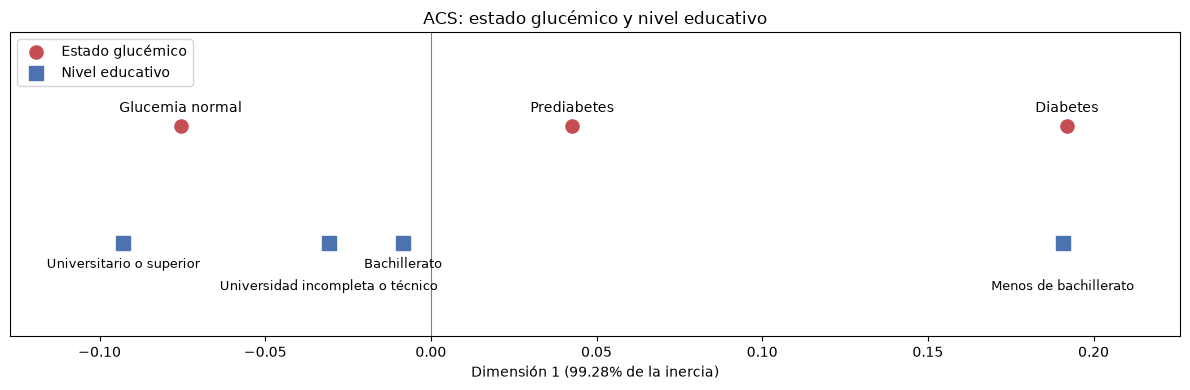

In [14]:
# Mapa unidimensional: la primera dimensión concentra casi toda la inercia
fig, ax = plt.subplots(figsize=(12, 4))

ax.scatter(coordenadas_filas.iloc[:, 0], [1] * len(coordenadas_filas),
           marker="o", s=90, color="#C44E52", label="Estado glucémico")
for etiqueta, punto in coordenadas_filas.iterrows():
    ax.annotate(etiqueta, (punto.iloc[0], 1), xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=10)

ax.scatter(coordenadas_columnas.iloc[:, 0], [0] * len(coordenadas_columnas),
           marker="s", s=90, color="#4C72B0", label="Nivel educativo")
# Las etiquetas se alternan en altura para que no se superpongan las categorías cercanas
for k, (etiqueta, punto) in enumerate(coordenadas_columnas.sort_values(coordenadas_columnas.columns[0]).iterrows()):
    ax.annotate(etiqueta, (punto.iloc[0], 0), xytext=(0, -18 if k % 2 == 0 else -34),
                textcoords="offset points", ha="center", fontsize=9)

inercia_dim1 = ca.eigenvalues_summary.iloc[0, 1]
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel=f"Dimensión 1 ({inercia_dim1} de la inercia)", yticks=[], ylim=(-0.8, 1.8),
       title="ACS: estado glucémico y nivel educativo")
ax.margins(x=0.12)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_acs_educacion.png", dpi=150, bbox_inches="tight")
plt.show()

La primera dimensión concentra el 99,3 % de la inercia, de modo que la asociación entre ambas variables puede representarse en una sola dimensión y la segunda (0,7 %) no aporta información relevante; por ello, el mapa se presenta de forma unidimensional. Además, las categorías más alejadas del origen son las que más contribuyen a esta dimensión: «Menos de bachillerato» (73,2 %) y «Universitario o superior» (23,1 %) entre los niveles educativos, y «Diabetes» (59,5 %) y «Glucemia normal» (34,3 %) entre los estados glucémicos.

En consecuencia, la dimensión 1 puede interpretarse como un gradiente socioeducativo del estado glucémico: en un extremo se ubican juntas la diabetes y la educación inferior al bachillerato, mientras que en el otro se ubican la glucemia normal y la educación universitaria. Por su parte, el bachillerato y la universidad incompleta quedan cerca del origen, lo que indica que su perfil glucémico es muy similar al promedio. Este patrón coincide con el de los perfiles y los residuos de las secciones anteriores; sin embargo, dada la baja inercia total, debe leerse como una tendencia y no como una separación marcada entre grupos.

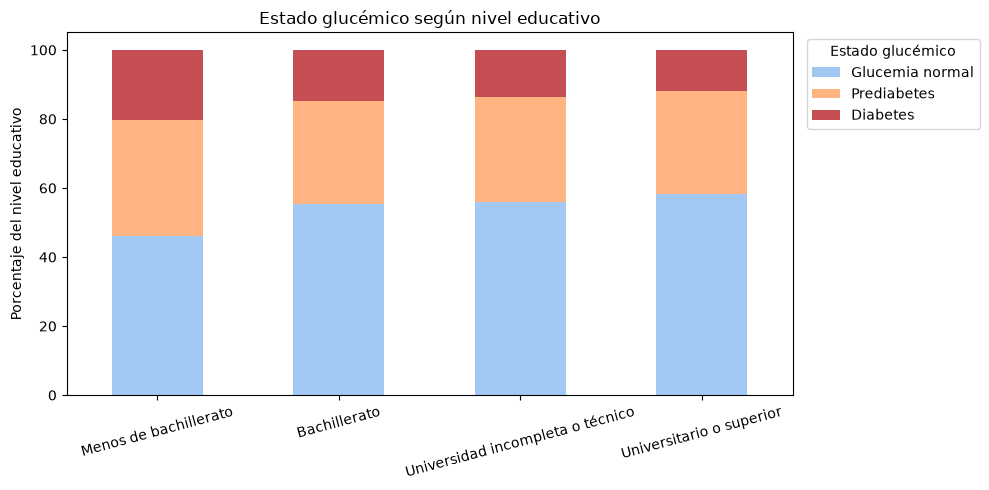

In [15]:
# Distribución porcentual del estado glucémico por nivel educativo
fig, ax = plt.subplots(figsize=(10, 5))
perfiles_educacion.T.plot(kind="bar", stacked=True, ax=ax,
                          color=["#A1C9F4", "#FFB482", "#C44E52"])
ax.set(xlabel="", ylabel="Porcentaje del nivel educativo",
       title="Estado glucémico según nivel educativo")
ax.tick_params(axis="x", labelrotation=15)
ax.legend(title="Estado glucémico", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "02_perfiles_educacion.png", dpi=150, bbox_inches="tight")
plt.show()

En síntesis, el ACS muestra que existe una asociación estadísticamente significativa pero débil entre el nivel educativo y el estado glucémico, que se organiza en un único gradiente: a mayor nivel educativo, menor proporción de diabetes y mayor proporción de glucemia normal. Este resultado concuerda con la literatura sobre determinantes sociales de la diabetes (Hill-Briggs et al., 2021), aunque, al tratarse de datos transversales, no permite establecer una relación causal; además, la debilidad de la asociación sugiere que el nivel educativo, por sí solo, explica una parte pequeña de las diferencias en el estado glucémico, lo cual justifica explorar de forma conjunta otras variables mediante el ACM.

## 6. Análisis de correspondencias múltiple (ACM)

### 6.1 Variables activas y suplementaria

In [16]:
ACTIVAS = ["grupo_edad", "sexo", "educacion", "raza_etnia", "pobreza",
           "seguridad_alimentaria", "seguro_medico", "tabaquismo", "obesidad_abdominal"]
SUPLEMENTARIA = ["estado_glucemico"]

n_categorias = sum(df_correspondencias[v].nunique() for v in ACTIVAS)
print(f"Variables activas: {len(ACTIVAS)}")
print(f"Categorías activas: {n_categorias}")

Variables activas: 9
Categorías activas: 28


En el ACM, las variables activas son las que construyen los ejes factoriales, mientras que las variables suplementarias no intervienen en su construcción y se proyectan después sobre el mapa (Greenacre, 2017). En este análisis, las nueve variables sociodemográficas y de estilo de vida son activas, de modo que los ejes describen los perfiles de la población, y el estado glucémico se incluye como suplementario, con el fin de observar con qué perfiles se asocia sin que influya en la forma en que estos se construyen.

### 6.2 Ajuste del modelo e inercia

In [17]:
# Modelo sin corrección: coordenadas, contribuciones y mapas
mca = prince.MCA(n_components=5, random_state=SEMILLA).fit(df_correspondencias[ACTIVAS])

# Modelo con la corrección de Benzécri: solo para reportar la inercia
mca_corregido = prince.MCA(n_components=5, correction="benzecri",
                           random_state=SEMILLA).fit(df_correspondencias[ACTIVAS])

inercia = pd.concat(
    {
        "Sin corrección": mca.eigenvalues_summary,
        "Corrección de Benzécri": mca_corregido.eigenvalues_summary,
    },
    axis=1,
)
display(inercia)

Sin corrección                                           \
              eigenvalue % of variance % of variance (cumulative)   
component                                                           
0                  0.241        11.44%                     11.44%   
1                  0.178         8.41%                     19.85%   
2                  0.149         7.08%                     26.93%   
3                  0.145         6.87%                     33.80%   
4                  0.121         5.74%                     39.53%   

          Corrección de Benzécri                                           
                      eigenvalue % of variance % of variance (cumulative)  
component                                                                  
0                          0.022        70.41%                     70.41%  
1                          0.006        18.33%                     88.74%  
2                          0.002         6.08%                     94.83%  
3                          0.001         4.76%                     99.58%  
4                          0.000         0.42%                    100.00%

En el ACM, la inercia total depende del número de categorías y no de la asociación entre las variables, por lo que los porcentajes de inercia sin corregir subestiman la información que capturan las primeras dimensiones (Greenacre, 2017). Por ello, se aplica la corrección de Benzécri, que conserva solo los valores propios mayores que 1/Q, donde Q es el número de variables activas, y los reescala. Los porcentajes corregidos son los que se reportan en los mapas; sin embargo, las coordenadas y las contribuciones se obtienen del modelo sin corregir, ya que la corrección solo afecta la escala de los valores propios.

### 6.3 Contribuciones de las categorías

In [18]:
# prince entrega las contribuciones como proporciones; se expresan en porcentaje
contribuciones = mca.column_contributions_ * 100
contribuciones.columns = [f"Dimensión {i + 1}" for i in range(contribuciones.shape[1])]

# Una categoría es relevante para un eje si supera la contribución promedio (100 / número de categorías)
umbral_contribucion = 100 / n_categorias
print(f"Contribución promedio: {umbral_contribucion:.2f} %")

for dimension in ["Dimensión 1", "Dimensión 2"]:
    print(f"\nCategorías con contribución superior al promedio en la {dimension.lower()}")
    relevantes = contribuciones[contribuciones[dimension] > umbral_contribucion]
    display(relevantes[[dimension]].sort_values(dimension, ascending=False).round(2))

Contribución promedio: 3.57 %

Categorías con contribución superior al promedio en la dimensión 1


,Dimensión 1
educacion__Universitario o superior,13.11
seguridad_alimentaria__Inseguridad alimentaria,10.92
pobreza__Bajo la línea de pobreza,10.65
pobreza__Por encima de la línea de pobreza,10.62
seguro_medico__Sin seguro médico,8.51
seguridad_alimentaria__Seguridad alimentaria plena,7.73
raza_etnia__Asiático no hispano,7.08
educacion__Menos de bachillerato,7.04
tabaquismo__Fumador actual,5.83



Categorías con contribución superior al promedio en la dimensión 2


,Dimensión 2
raza_etnia__Asiático no hispano,12.85
grupo_edad__60 años o más,12.67
tabaquismo__Exfumador,12.48
obesidad_abdominal__Sin obesidad abdominal,11.58
raza_etnia__Blanco no hispano,8.44
grupo_edad__20 a 39 años,7.88
obesidad_abdominal__Con obesidad abdominal,7.66
seguro_medico__Sin seguro médico,6.01
educacion__Universitario o superior,4.40
tabaquismo__Nunca fumador,3.86


### 6.4 Proyección del estado glucémico

In [19]:
coord_activas = mca.column_coordinates(df_correspondencias[ACTIVAS])

# La variable suplementaria se proyecta con los mismos participantes del ajuste;
# prince devuelve filas vacías para las categorías activas, que se eliminan
coord_suplementaria = mca.column_coordinates(df_correspondencias[SUPLEMENTARIA]).dropna()

print("Coordenadas del estado glucémico (suplementaria)")
display(coord_suplementaria.iloc[:, :2].round(3))

Coordenadas del estado glucémico (suplementaria)


,0,1
estado_glucemico__Diabetes,0.077,-0.407
estado_glucemico__Glucemia normal,0.010,0.218
estado_glucemico__Prediabetes,-0.055,-0.193


### 6.5 Mapa de categorías

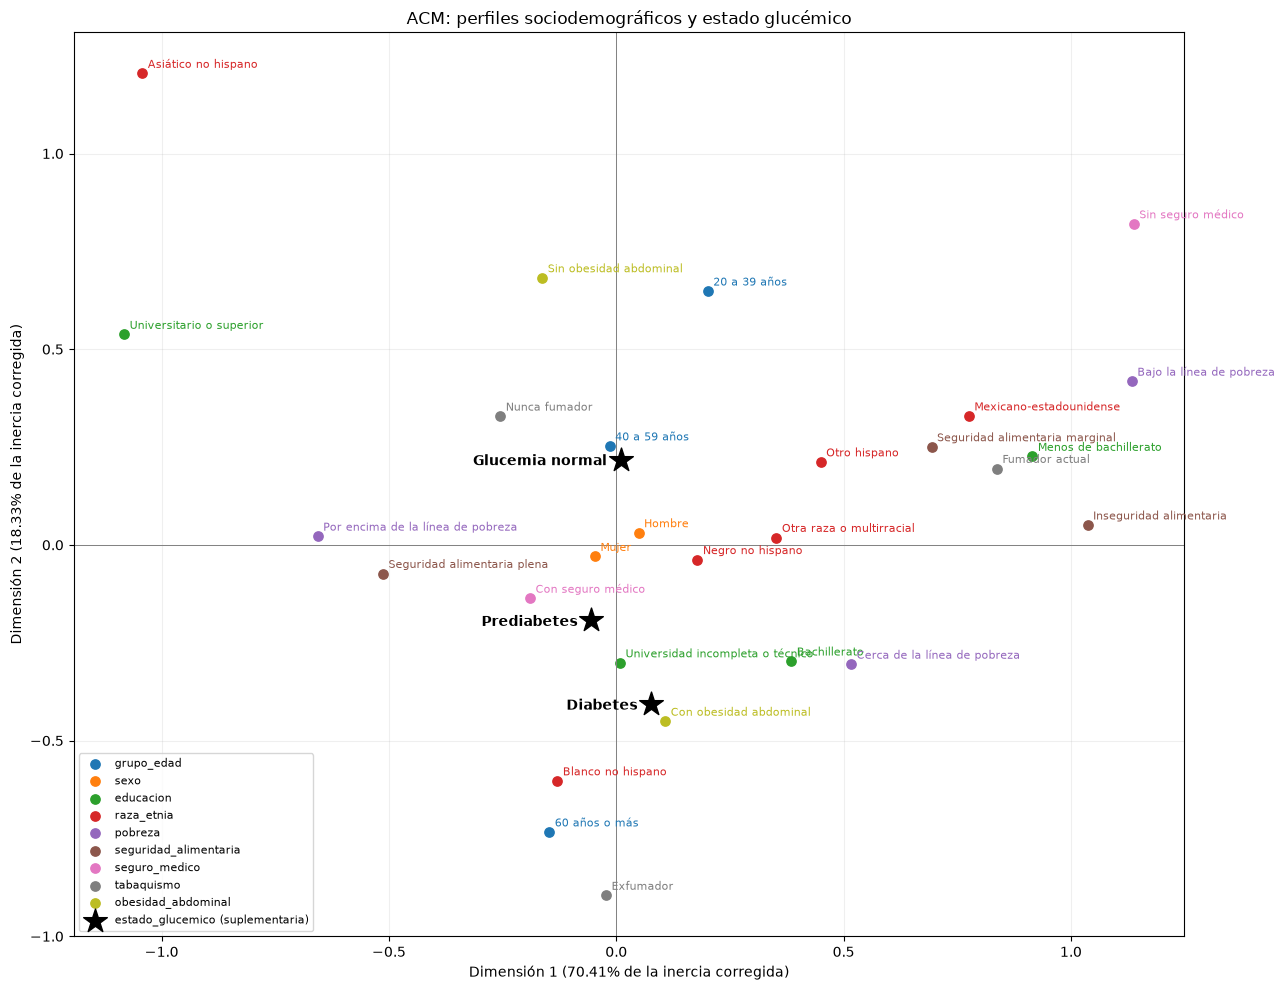

In [20]:
porcentaje = mca_corregido.eigenvalues_summary["% of variance"]

variables_activas = coord_activas.index.str.split("__").str[0]
etiquetas_activas = coord_activas.index.str.split("__").str[1]
paleta = dict(zip(ACTIVAS, sns.color_palette("tab10", len(ACTIVAS))))

fig, ax = plt.subplots(figsize=(13, 10))

for variable in ACTIVAS:
    mascara = variables_activas == variable
    ax.scatter(coord_activas.loc[mascara, 0], coord_activas.loc[mascara, 1],
               s=45, color=paleta[variable], label=variable)
    for x, y, etiqueta in zip(coord_activas.loc[mascara, 0], coord_activas.loc[mascara, 1],
                              etiquetas_activas[mascara]):
        ax.annotate(etiqueta, (x, y), xytext=(4, 4), textcoords="offset points",
                    fontsize=8, color=paleta[variable])

# Variable suplementaria con un marcador distinto
ax.scatter(coord_suplementaria[0], coord_suplementaria[1], marker="*", s=320,
           color="black", label="estado_glucemico (suplementaria)", zorder=3)
for etiqueta, punto in coord_suplementaria.iterrows():
    ax.annotate(etiqueta.split("__")[1], (punto[0], punto[1]), xytext=(-10, -4),
                textcoords="offset points", ha="right", fontsize=10, fontweight="bold")

ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="gray", linewidth=0.7)
ax.set(xlabel=f"Dimensión 1 ({porcentaje.iloc[0]} de la inercia corregida)",
       ylabel=f"Dimensión 2 ({porcentaje.iloc[1]} de la inercia corregida)",
       title="ACM: perfiles sociodemográficos y estado glucémico")
ax.legend(fontsize=8, loc="best")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "03_acm_mapa.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.6 Verificación con tablas cruzadas

In [21]:
def asociacion_con_glucemia(variable):
    """Porcentaje de cada estado glucémico por categoría, chi-cuadrado y V de Cramér."""
    tabla_obs = pd.crosstab(df_correspondencias[variable], df_correspondencias["estado_glucemico"])
    tabla_obs = tabla_obs[ORDEN_GLUCEMIA]
    chi2_v, p_v, gl_v, _ = chi2_contingency(tabla_obs, correction=False)
    n_v = tabla_obs.to_numpy().sum()
    v = np.sqrt(chi2_v / (n_v * (min(tabla_obs.shape) - 1)))
    porcentajes = (pd.crosstab(df_correspondencias[variable], df_correspondencias["estado_glucemico"],
                               normalize="index") * 100)[ORDEN_GLUCEMIA].round(1)
    return porcentajes, {"variable": variable, "chi2": round(chi2_v, 2), "gl": gl_v,
                         "p_valor": p_v, "v_cramer": round(v, 3)}


resumen = []
for variable in ACTIVAS:
    porcentajes, estadisticos = asociacion_con_glucemia(variable)
    resumen.append(estadisticos)

resumen = pd.DataFrame(resumen).set_index("variable").sort_values("v_cramer", ascending=False)
print("Asociación de cada variable activa con el estado glucémico")
display(resumen)

Asociación de cada variable activa con el estado glucémico


,chi2,gl,p_valor,v_cramer
variable,,,,
grupo_edad,687.97,4,1.404418e-147,0.289
obesidad_abdominal,211.65,2,1.095758e-46,0.227
raza_etnia,81.67,10,2.364633e-13,0.100
seguro_medico,31.37,2,1.542226e-07,0.087
tabaquismo,55.85,4,2.160048e-11,0.082
educacion,37.66,6,1.306847e-06,0.068
sexo,14.73,2,6.334926e-04,0.060
seguridad_alimentaria,8.79,4,6.653805e-02,0.033
pobreza,8.63,4,7.098513e-02,0.032


In [22]:
# Porcentajes por categoría de las tres variables más asociadas con el estado glucémico
for variable in resumen.index[:3]:
    porcentajes, _ = asociacion_con_glucemia(variable)
    print(f"\n{variable}: porcentaje de cada estado glucémico por categoría")
    display(porcentajes)


grupo_edad: porcentaje de cada estado glucémico por categoría


estado_glucemico,Glucemia normal,Prediabetes,Diabetes
grupo_edad,,,
20 a 39 años,82.3,15.2,2.5
40 a 59 años,53.3,32.5,14.2
60 años o más,33.6,41.7,24.7



obesidad_abdominal: porcentaje de cada estado glucémico por categoría


estado_glucemico,Glucemia normal,Prediabetes,Diabetes
obesidad_abdominal,,,
Con obesidad abdominal,45.8,35.1,19.1
Sin obesidad abdominal,67.9,24.3,7.9



raza_etnia: porcentaje de cada estado glucémico por categoría


estado_glucemico,Glucemia normal,Prediabetes,Diabetes
raza_etnia,,,
Asiático no hispano,50.9,34.6,14.6
Blanco no hispano,61.2,26.9,11.8
Mexicano-estadounidense,56.1,26.0,17.9
Negro no hispano,44.3,38.5,17.2
Otra raza o multirracial,58.5,26.3,15.2
Otro hispano,53.6,31.2,15.2


### 6.7 Interpretación del ACM

Con la corrección de Benzécri, las dos primeras dimensiones recogen el 88,7 % de la inercia (70,4 % y 18,3 %), por lo que el mapa resume adecuadamente la estructura de asociación entre las variables activas. La dimensión 1 corresponde a un gradiente socioeconómico: en un extremo se ubican las categorías universitario o superior, por encima de la línea de pobreza y seguridad alimentaria plena, y en el otro, menos de bachillerato, bajo la línea de pobreza, inseguridad alimentaria y sin seguro médico. La dimensión 2, en cambio, opone a los adultos de 20 a 39 años, sin obesidad abdominal y que nunca han fumado, a los adultos de 60 años o más, con obesidad abdominal y exfumadores, de modo que representa un eje de edad y de riesgo cardiometabólico.

Al proyectar el estado glucémico como variable suplementaria, sus tres categorías se ordenan a lo largo de la dimensión 2 (glucemia normal 0,22; prediabetes −0,19; diabetes −0,41) y prácticamente no se desplazan sobre la dimensión 1. Así, el estado glucémico se asocia más con la edad y la obesidad abdominal que con el perfil socioeconómico. No obstante, las coordenadas de las categorías suplementarias son pequeñas frente a las de las activas, lo que indica una asociación moderada, coherente con lo observado en el ACS.

Las pruebas de chi-cuadrado confirman esta lectura. La edad (V = 0,289) y la obesidad abdominal (V = 0,227) presentan las asociaciones más intensas, mientras que la raza o etnia, el seguro médico, el tabaquismo, la educación y el sexo muestran asociaciones significativas pero débiles (V entre 0,060 y 0,100). Por su parte, la pobreza (p = 0,071) y la seguridad alimentaria (p = 0,067) no alcanzan significancia al 5 %. En cuanto a las proporciones, la diabetes pasa del 2,5 % en los adultos de 20 a 39 años al 24,7 % en los de 60 años o más, grupo que además concentra la mayor proporción de prediabetes (41,7 %); de igual forma, la diabetes es más del doble en quienes tienen obesidad abdominal (19,1 %) que en quienes no la tienen (7,9 %).

Sin embargo, la cercanía de algunas categorías a la diabetes en el mapa refleja la edad más que una relación propia. Por ejemplo, el 56,8 % de los exfumadores tiene 60 años o más, frente al 26,0 % de los fumadores actuales, lo que explica que los exfumadores presenten más diabetes (20,5 %) que los fumadores actuales (9,8 %). Algo similar ocurre con los blancos no hispanos, que se ubican cerca de la diabetes por ser el grupo de mayor edad (44,8 % con 60 años o más), aunque son el grupo con la menor proporción de diabetes (11,8 %); en contraste, las proporciones más altas se observan en los mexicano-estadounidenses (17,9 %) y en los negros no hispanos (17,2 %), estos últimos además con la mayor proporción de prediabetes (38,5 %). Del mismo modo, las personas sin seguro médico presentan menos diabetes que las aseguradas (12,6 % frente a 15,0 %), ya que son mayoritariamente jóvenes (48,0 % entre 20 y 39 años). Por lo tanto, el ACM describe asociaciones entre categorías, pero no permite aislar la relación de cada variable con el estado glucémico, ya que no controla por las demás (Greenacre, 2017).

## 7. Conclusiones

En respuesta a la pregunta guía, los perfiles que más se asocian con el estado glucémico son los de mayor edad y con obesidad abdominal, ya que ambas variables concentran las asociaciones más intensas tanto en el ACM como en las pruebas de chi-cuadrado. Por su parte, el nivel educativo muestra un gradiente consistente, pues la diabetes disminuye del 20,2 % en quienes no terminaron el bachillerato al 11,8 % en quienes tienen formación universitaria, aunque con una asociación débil (V = 0,068). En cambio, la pobreza y la seguridad alimentaria no mostraron una asociación significativa con el estado glucémico en esta muestra.

Estos resultados matizan el planteamiento inicial. Si bien la literatura señala que los determinantes sociales influyen tanto en el riesgo como en el manejo de la diabetes (Comisión sobre Determinantes Sociales de la Salud, 2008; Hill-Briggs et al., 2021), en este análisis el gradiente socioeconómico aparece de forma débil frente a la edad y la obesidad abdominal. Aun así, ambos enfoques no se excluyen, dado que el sobrepeso y la obesidad figuran entre los criterios para el tamizaje de la diabetes (American Diabetes Association Professional Practice Committee, 2025) y la literatura los vincula con condiciones como el entorno alimentario y el nivel educativo (Hill-Briggs et al., 2021). De esta manera, el abordaje de la diabetes puede ir más allá del ámbito biomédico e incluir la educación y el acceso a una alimentación saludable y a los servicios de salud, sobre todo en los grupos con menos recursos.

Finalmente, estas conclusiones deben leerse a la luz de varias limitaciones. En primer lugar, el diseño de NHANES es transversal, por lo que los resultados describen asociaciones y no permiten afirmar que una variable cause o anteceda el desarrollo de la diabetes. En segundo lugar, se excluyó cerca del 17 % de la población de estudio, principalmente por no reportar ingresos. En tercer lugar, el análisis no incorporó los pesos muestrales de la encuesta, de modo que las proporciones describen la muestra y no a la población de Estados Unidos (National Center for Health Statistics, 2020). Por último, el estado glucémico se definió con una sola medición de HbA1c, mientras que el diagnóstico clínico requiere confirmación (American Diabetes Association Professional Practice Committee, 2025); además, las personas con diabetes bien controlada pueden quedar clasificadas como prediabetes o glucemia normal.

## Referencias

Alberti, K. G. M. M., Eckel, R. H., Grundy, S. M., Zimmet, P. Z., Cleeman, J. I., Donato, K. A., Fruchart, J.-C., James, W. P. T., Loria, C. M., & Smith, S. C., Jr. (2009). Harmonizing the metabolic syndrome. *Circulation, 120*(16), 1640–1645. https://doi.org/10.1161/CIRCULATIONAHA.109.192644

American Diabetes Association Professional Practice Committee. (2025). 2. Diagnosis and classification of diabetes: Standards of Care in Diabetes—2025. *Diabetes Care, 48*(Supl. 1), S27–S49. https://doi.org/10.2337/dc25-S002

Comisión sobre Determinantes Sociales de la Salud. (2008). *Subsanar las desigualdades en una generación: Alcanzar la equidad sanitaria actuando sobre los determinantes sociales de la salud*. Organización Mundial de la Salud.

Greenacre, M. (2017). *Correspondence analysis in practice* (3.ª ed.). Chapman and Hall/CRC. https://doi.org/10.1201/9781315369983

Heredia-Morales, M., Ramírez-Jaime, L. E., & Miranda-Cota, G. A. (2023). Determinantes sociales de salud y diabetes mellitus tipo 2: Una revisión de alcance. En *Salud y alimentación desde una perspectiva sociocultural* (pp. 204–220). Astra Ediciones. https://doi.org/10.61728/AE24140119

Hill-Briggs, F., Adler, N. E., Berkowitz, S. A., Chin, M. H., Gary-Webb, T. L., Navas-Acien, A., Thornton, P. L., & Haire-Joshu, D. (2021). Social determinants of health and diabetes: A scientific review. *Diabetes Care, 44*(1), 258–279. https://doi.org/10.2337/dci20-0053

Hirode, G., & Wong, R. J. (2020). Trends in the prevalence of metabolic syndrome in the United States, 2011–2016. *JAMA, 323*(24), 2526–2528. https://doi.org/10.1001/jama.2020.4501

National Center for Health Statistics. (2020). *NHANES 2017-2018: Demographic variables and sample weights (DEMO_J)* [Documentación de datos]. Centers for Disease Control and Prevention. https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm

National Center for Health Statistics. (s.f.). *National Health and Nutrition Examination Survey*. Centers for Disease Control and Prevention. https://www.cdc.gov/nchs/nhanes/

Organización Panamericana de la Salud. (s.f.). *Diabetes*. https://www.paho.org/es/temas/diabetes

Wang, Q., Würtz, P., Auro, K., Mäkinen, V.-P., Kangas, A. J., Soininen, P., Tiainen, M., Tynkkynen, T., Jokelainen, J., Santalahti, K., Salmi, M., Blankenberg, S., Zeller, T., Viikari, J., Kähönen, M., Lehtimäki, T., Salomaa, V., Perola, M., Jalkanen, S., . . . Ala-Korpela, M. (2016). Metabolic profiling of pregnancy: Cross-sectional and longitudinal evidence. *BMC Medicine, 14*, Artículo 205. https://doi.org/10.1186/s12916-016-0733-0